# CSCI 3003 - Data Visualization

## Lab 2: Visualizing Qualitative Variables

**Name:** Steve Tatsiguai
**Date:** 2026-09-03  
**Version:** Student notebook

> Replace the name and date above before submitting.


## Purpose and learning objectives

This lab focuses on displaying **qualitative variables**: variables whose values place observations into categories. By the end, you should be able to:

- Count observations in categories with `.value_counts()`.
- Create and label a bar chart for one qualitative variable.
- Create a two-way table with `pd.crosstab()`.
- Create and interpret a grouped bar chart for two qualitative variablejjs.
- Investigate a question using qualitative variables from the class survey.

Each `loan50.csv` example is followed by practice with different variables. The final section uses the de-identified class survey.


## I. Import the packages

Reuse the Lab 1 imports. Recall that `pd` is the conventional nickname for pandas and `plt` is the conventional nickname for `matplotlib.pyplot`.


In [103]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## II. Prepare and save the class survey data

Lab 1 loaded the survey and gave its long questions shorter names. Repeat that preparation briefly, then save a cleaned CSV that will be easier to reuse.


In [104]:
survey_raw_file = Path("student_survey_fall2026.csv")
survey_raw_file.exists()

True

The path check should display `True`. If it does not, use the file-path checks from Lab 1 before continuing.


In [105]:
survey_raw = pd.read_csv(survey_raw_file, encoding="cp1252")
survey_raw.shape

(12, 14)

In [106]:
survey_raw.columns

Index(['What is your age in years?', 'How do you describe your gender?',
       'What is your major or intended major?',
       'Where would you place yourself on this scale today?\n1 = Strongly introverted; 3 = About equally introverted and extroverted;Ê 5 = Strongly extroverted\n',
       'Which study setting do you usually prefer?',
       'What is your favorite ice-cream flavor?',
       'Have you completed Elementary Statistics or an equivalent course?',
       'In what year did you complete (or will complete) Elementary Statistics or its equivalent?\n\nEnter the four-digit year, or `0` if you have not completed it.\n',
       'ÊWhich statement best describes your overall experience with statistics?',
       'How confident are you interpreting a graph or statistical summary?\n1 = Not yet confident; 5 = Very confident\n',
       'How much programming experience do you have?',
       'Which programming languages have you used? Select all that apply.',
       'Have you used Visual St

### Rename the survey variables

Apply the same `snake_case` names introduced in Lab 1. Saving the renamed DataFrame as `survey` leaves `survey_raw` unchanged.


In [107]:
survey_column_names = {
    survey_raw.columns[0]: "age_years",
    survey_raw.columns[1]: "gender_identity",
    survey_raw.columns[2]: "intended_major",
    survey_raw.columns[3]: "introversion_extroversion",
    survey_raw.columns[4]: "preferred_study_setting",
    survey_raw.columns[5]: "favorite_ice_cream_flavor",
    survey_raw.columns[6]: "completed_statistics",
    survey_raw.columns[7]: "statistics_completion_year",
    survey_raw.columns[8]: "statistics_experience",
    survey_raw.columns[9]: "graph_confidence",
    survey_raw.columns[10]: "programming_experience",
    survey_raw.columns[11]: "programming_languages",
    survey_raw.columns[12]: "vscode_experience",
    survey_raw.columns[13]: "troubleshooting_confidence",
}

survey = survey_raw.rename(columns=survey_column_names)
survey.columns

Index(['age_years', 'gender_identity', 'intended_major',
       'introversion_extroversion', 'preferred_study_setting',
       'favorite_ice_cream_flavor', 'completed_statistics',
       'statistics_completion_year', 'statistics_experience',
       'graph_confidence', 'programming_experience', 'programming_languages',
       'vscode_experience', 'troubleshooting_confidence'],
      dtype='str')

### Save and reload the cleaned survey

`.to_csv()` saves a DataFrame as a CSV. The argument `index=False` prevents pandas from adding row numbers as another column. Keep this de-identified class file inside the private course workspace.


In [108]:
survey_clean_file = Path("student_survey_fall2026_clean.csv")
survey.to_csv(survey_clean_file, index=False)
survey_clean_file.exists()

True

Reload the cleaned file to confirm that it is ready for later analysis. Display only its dimensions and column names, not individual response rows.


In [109]:
survey = pd.read_csv(survey_clean_file)
print(survey.shape)
survey.columns

(12, 14)


Index(['age_years', 'gender_identity', 'intended_major',
       'introversion_extroversion', 'preferred_study_setting',
       'favorite_ice_cream_flavor', 'completed_statistics',
       'statistics_completion_year', 'statistics_experience',
       'graph_confidence', 'programming_experience', 'programming_languages',
       'vscode_experience', 'troubleshooting_confidence'],
      dtype='str')

**Question 1:** What file did `.to_csv()` create, and why did we use `index=False`?

**Answer:**  `. to_csv()` created survey_clean_file and `index=False` to prevent pandas from adding row_numbers like an another column




## III. Load the loan data

Use the Lab 1 loading workflow for `loan50.csv`, then begin the new work with qualitative variables.


In [110]:
loan_file = Path("loan50.csv")
loan_file.exists()

True

In [111]:
loans = pd.read_csv(loan_file)
loans.columns

Index(['state', 'emp_length', 'term', 'homeownership', 'annual_income',
       'verified_income', 'debt_to_income', 'total_credit_limit',
       'total_credit_utilized', 'num_cc_carrying_balance', 'loan_purpose',
       'loan_amount', 'grade', 'interest_rate', 'public_record_bankrupt',
       'loan_status', 'has_second_income', 'total_income'],
      dtype='str')

### Identify qualitative variables

A qualitative variable describes categories rather than a measured amount. In this dataset, examples include:

- `loan_purpose`, such as `credit_card` or `home_improvement`;
- `homeownership`, such as `rent`, `mortgage`, or `own`; and
- `grade`, an ordered loan-risk category from A through E in this sample.

A number can also act as a category. For example, `term` contains `36` and `60`, but those values represent two loan-term groups here.

**Question 2:** Name two other qualitative variables in `loans`. Explain briefly why each is qualitative.

**Answer:**  `loan_status` with `fully paid` or `current`



## IV. One qualitative variable: frequency tables

Before plotting categories, count them. `.value_counts()` counts how many times each distinct value occurs. By default, it orders the categories from the most frequent to the least frequent.

### Worked example: loan purpose

The following code answers: **How many loans in the sample have each loan purpose?**


In [112]:
purpose_counts = loans["loan_purpose"].value_counts()
purpose_counts

loan_purpose
debt_consolidation    23
credit_card           13
home_improvement       5
other                  4
car                    2
house                  1
small_business         1
renewable_energy       1
Name: count, dtype: int64

**Interpretation:** Each row is a category and its frequency. For example, the output shows that debt consolidation is the most common loan purpose in this sample. These are counts from 50 sampled loans, not percentages for all Lending Club loans.

### Practice: frequency table

Create a frequency table for `homeownership`. Then answer the question below.

**Question 3:** Which homeownership category is most common, and how many sampled borrowers are in that category?


In [113]:
homeownership_counts = loans["homeownership"].value_counts()
homeownership_counts

homeownership
mortgage    26
rent        21
own          3
Name: count, dtype: int64

**Answer:** Mortgage is the most common category with 26 sampled




## V. One qualitative variable: bar charts

A bar chart represents each category with a separate bar. The bar length or height represents its count.

We can call `.plot.bar()` on a pandas Series containing category counts. The function returns a Matplotlib **Axes** object. Saving that object as `ax` lets us add a title and axis labels.

Note: to use `.plot.bar()`, Matplotlib must still be installed. Pandas imports and uses it internally when the plotting command runs. If Matplotlib is not installed, pandas will raise an ImportError.

### Worked example: loan purpose


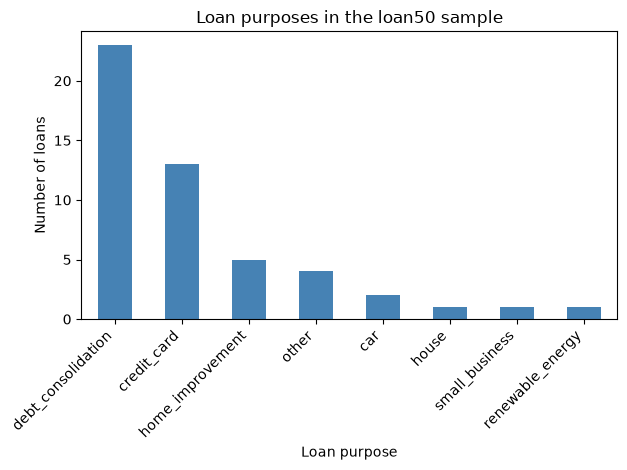

In [114]:
purpose_counts = loans["loan_purpose"].value_counts()

ax = purpose_counts.plot.bar(color="steelblue")
ax.set_title("Loan purposes in the loan50 sample")
ax.set_xlabel("Loan purpose")
ax.set_ylabel("Number of loans")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The category labels are rotated because several are too long to fit horizontally. `plt.tight_layout()` adds enough space so labels are not cut off.

### Practice: one-variable bar chart

Create a bar chart of `homeownership` using the `homeownership_counts` Series from Practice A. Give the chart a descriptive title and label both axes.

**Question 4:** What does the tallest bar represent? Describe the largest difference you see between categories.


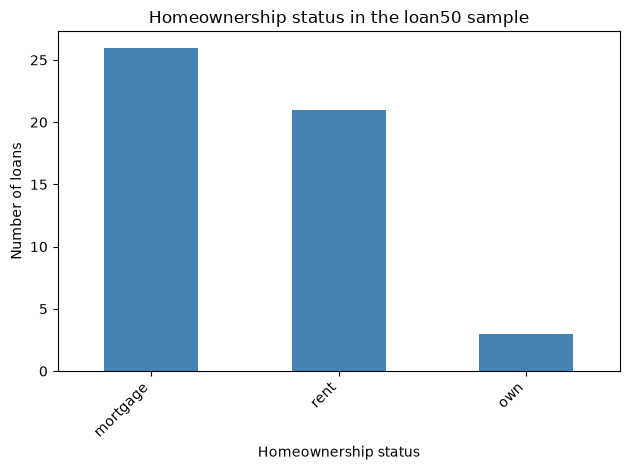

In [115]:
homeownership_counts = loans["homeownership"].value_counts()

ax = homeownership_counts.plot.bar(color="steelblue")
ax.set_title("Homeownership status in the loan50 sample")
ax.set_xlabel("Homeownership status")
ax.set_ylabel("Number of loans")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Answer:** The tallest bar represeent mortgage and the smallest bar represent own, which means more people have mortgage than own a home




## VI. Two qualitative variables: two-way tables

A **two-way table**, also called a contingency table or cross-tabulation, counts combinations of two qualitative variables.

`pd.crosstab(rows, columns)` creates the table. The first variable supplies the row categories, and the second supplies the column categories.

### Worked example: homeownership and loan grade

The following table answers: **How many sampled loans have each combination of homeownership and loan grade?**


In [116]:
ownership_grade_table = pd.crosstab(
    loans["homeownership"],
    loans["grade"],
    rownames=["Homeownership"],
    colnames=["Loan grade"],
)

ownership_grade_table

Loan grade,A,B,C,D,E
Homeownership,,,,,
mortgage,7,10,4,3,2
own,0,1,1,1,0
rent,8,8,1,4,0


Read one cell at a time. For example, the cell at row `mortgage` and column `B` counts sampled borrowers with a mortgage whose loan has grade B. A zero means that combination does not occur in this sample.

### Practice C: two-way table

Create a two-way table with `verified_income` in the rows and `term` in the columns.

**Question 5:** For borrowers whose income is `Source Verified`, which loan term is more common in this sample? Support your answer with counts.


In [117]:
source_verified_table = pd.crosstab(
    loans["verified_income"],
    loans["term"],
    rownames=["Verified Income"],
    colnames=["Term"],
)

source_verified_table

Term,36,60
Verified Income,,
Not Verified,16,5
Source Verified,15,5
Verified,5,4


**Answer:**  `not_verified` in term 36 is the most common




## VII. Two qualitative variables: grouped bar charts

A grouped bar chart places bars for the second variable next to one another within each category of the first variable. It can make patterns in a two-way table easier to compare.

Use the two-way table as the plotting data. Calling `.plot.bar()` creates one group for each row and one colored bar for each column.

### Worked example: homeownership and loan grade


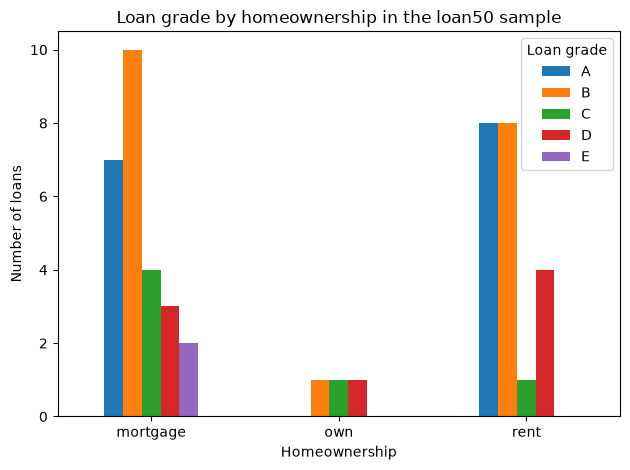

In [118]:
ax = ownership_grade_table.plot.bar()
ax.set_title("Loan grade by homeownership in the loan50 sample")
ax.set_xlabel("Homeownership")
ax.set_ylabel("Number of loans")
ax.legend(title="Loan grade")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

A bar represents a count for one combination of categories. Compare bar heights within a homeownership group and across groups, but remember that the groups contain different total numbers of borrowers.

### Practice D: grouped bar chart

Plot the `verification_term_table` from Practice C as a grouped bar chart. Add a descriptive title, axis labels, and a legend title.

**Question 6:** Describe one visible pattern. Then explain why this 50-loan sample is not enough to claim that income verification determines loan term.


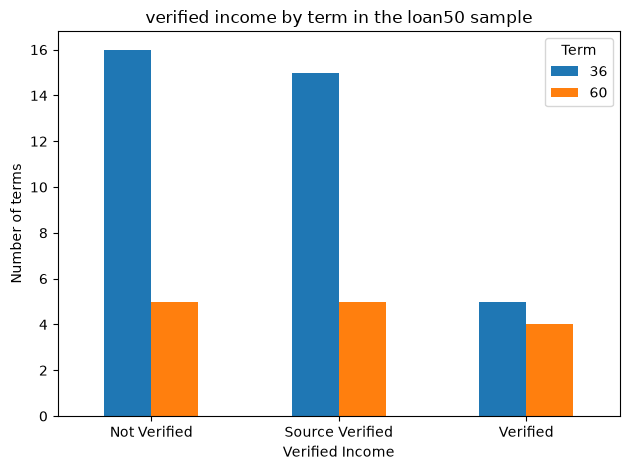

In [119]:
ax = source_verified_table.plot.bar()
ax.set_title("verified income by term in the loan50 sample")
ax.set_xlabel("Verified Income")
ax.set_ylabel("Number of terms")
ax.legend(title="Term")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Answer:** verified income on term60 are more consistent than that of term 36 as it goes all over the place




## VIII. Open practice: our class survey

Use the cleaned copy of the de-identified `student_survey_fall2026.csv` file to complete both a one-variable investigation and a two-variable investigation.

Privacy rules:

- Do not attempt to identify classmates.
- Do not display direct identifiers.
- Do not use `gender_identity` or another demographic variable if the output would display a small category that could identify a student.
- Prefer non-sensitive variables such as study setting, ice-cream flavor, prior statistics experience, programming experience, or VS Code experience.

The `survey` DataFrame already contains the cleaned variable names created and saved in Section II. Display the names again before choosing your variables.


In [120]:
survey.columns

Index(['age_years', 'gender_identity', 'intended_major',
       'introversion_extroversion', 'preferred_study_setting',
       'favorite_ice_cream_flavor', 'completed_statistics',
       'statistics_completion_year', 'statistics_experience',
       'graph_confidence', 'programming_experience', 'programming_languages',
       'vscode_experience', 'troubleshooting_confidence'],
      dtype='str')

### One-variable investigation

**Question 7:** Ask how observations are distributed across the categories of one qualitative variable. Create a frequency table and a labeled bar chart.

**Your investigation question:**



Use the next cell for your code. You may add more cells.


In [121]:
loans.head

<bound method NDFrame.head of    state  emp_length  term homeownership  annual_income  verified_income  \
0     NJ         3.0    60          rent          59000     Not Verified   
1     CA        10.0    36          rent          60000     Not Verified   
2     SC         NaN    36      mortgage          75000         Verified   
3     CA         0.0    36          rent          75000     Not Verified   
4     OH         4.0    60      mortgage         254000     Not Verified   
5     IN         6.0    36      mortgage          67000  Source Verified   
6     NY         2.0    36          rent          28800  Source Verified   
7     MO        10.0    36      mortgage          80000     Not Verified   
8     FL         6.0    60          rent          34000     Not Verified   
9     FL         3.0    60      mortgage          80000  Source Verified   
10    MD         8.0    36          rent          73000  Source Verified   
11    HI        10.0    36      mortgage         120000   

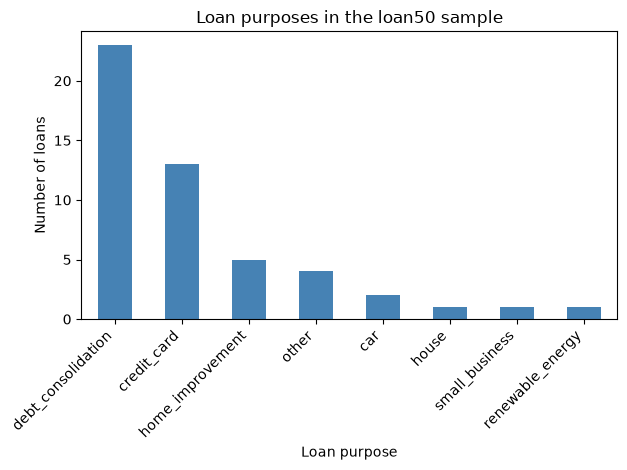

In [122]:
purpose_counts = loans["loan_purpose"].value_counts()

ax = purpose_counts.plot.bar(color="steelblue")
ax.set_title("Loan purposes in the loan50 sample")
ax.set_xlabel("Loan purpose")
ax.set_ylabel("Number of loans")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Answer your investigation question using specific evidence from the frequency table and bar chart.

**Answer:** Debt consolidation is the most common loan purpose with 23 loans. Credit card is next with 13 loans. House, small business, and renewable energy are the least common, with only 1 loan each.




### Two-variable investigation

**Question 8:** Ask how two qualitative variables are related in this class. Create a two-way table and a labeled grouped bar chart.

**Your investigation question:**



Use the next cell for your code. You may add more cells.


In [123]:
state_homeownership_table = pd.crosstab(
    loans["homeownership"],
    loans["state"],
    rownames=["Homeownership"],
    colnames=["State"],
)

state_homeownership_table

State,AZ,CA,CT,FL,HI,IL,IN,MA,MD,MI,...,NJ,NV,NY,OH,RI,SC,TX,VA,WI,WV
Homeownership,,,,,,,,,,,,,,,,,,,,,
mortgage,0,2,0,2,1,0,1,1,1,1,...,1,2,0,1,1,1,5,0,1,1
own,1,0,0,0,0,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
rent,0,7,1,1,1,3,0,1,2,0,...,2,0,1,0,0,0,0,1,0,0


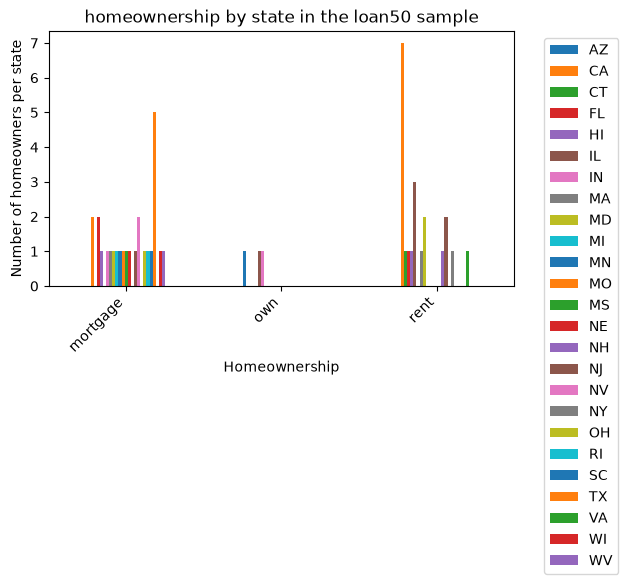

In [124]:
ax = state_homeownership_table.plot.bar()
ax.set_title("homeownership by state in the loan50 sample")
ax.set_xlabel("Homeownership")
ax.set_ylabel("Number of homeowners per state")
ax.legend(title="states")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Answer your investigation question using specific evidence from the two-way table and grouped bar chart

**Answer:** Homeownership seems to vary by state. California stands out the most, with 7 renters and 5 people with mortgages. Most of the other states only have about 1 or 2 people in each homeownership category, so California has the biggest difference compared to the others.




## IX. Submission check

Before exporting:

- Add your name and date, and complete Questions 1-8.
- Check that plots are labeled and survey outputs protect student privacy.
- Restart the kernel, run all cells, and resolve any errors.
- Export to HTML and confirm that all work is visible.
